In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "07"

# 07 · What the emission does to the grid voltage

**Question:** if one inverter emits at its IEEE 1547 current limits, is the grid voltage still within
the voltage limits (EN 50160:2007 and IEEE Std 519-2022)?

This is the link to hosting capacity: the current limits are set for the device, the voltage limits for
the grid, and the grid impedance decides how one becomes the other.

Caveat: EN 50160 limits apply to 10-minute values over a week (95 % of the time). Here we compare
single 10-cycle snapshots, so this is an indication, not a compliance test.

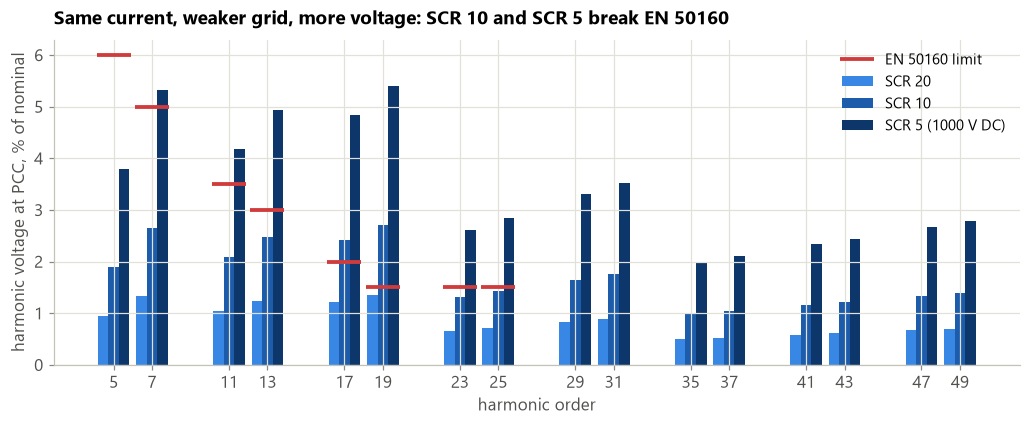

In [2]:
b = A.load("bench_hil404.csv"); s = A.load("scenarios_hil404.csv")
f = s[s.scenario == "F"].drop(columns="scenario").assign(grid="SCR 5")
d = pd.concat([b[b.grid.isin(["SCR 20", "SCR 10"])], f]).query("order > 1")
en = pd.Series(A.EN50160)
fig, ax = A.panels(1, h=4.0)
for i, g in enumerate(["SCR 20", "SCR 10", "SCR 5"]):
    x = d[d.grid == g]
    ax[0].bar(x.order + (i - 1) * 0.55, x.V_pct, 0.55, color=A.GRID_COLOR[g], label=g + (" (1000 V DC)" if g == "SCR 5" else ""))
ax[0].plot(en.index, en.values, "_", color=A.BAD, ms=22, mew=2.5, label="EN 50160 limit")
A.orders_axis(ax[0]); ax[0].set_ylabel("harmonic voltage at PCC, % of nominal")
ax[0].set_title("Same current, weaker grid, more voltage: SCR 10 and SCR 5 break EN 50160")
ax[0].legend()
A.save(fig, "07_voltage_per_order", d[["grid", "order", "I_pct", "V_pct"]])

**Reading.** The same harmonic currents (full request) produce about twice the voltage on SCR 10 as on
SCR 20, and four times on SCR 5. The red marks are the EN 50160 limits (defined up to the 25th order).
On SCR 20 everything is under the marks; on SCR 10 the 17th and 19th are over; on SCR 5 most orders are over.

## How much emission does each grid allow?

| grid | largest master meeting EN 50160 | worst ratio at master 1 | binding order |
|---|---|---|---|
| SCR 20 | > 1 (full request is fine) | 0.901 | 19 |
| SCR 10 | 0.555 | 1.8 | 19 |
| SCR 5 | 0.277 | 3.57 | 19 |

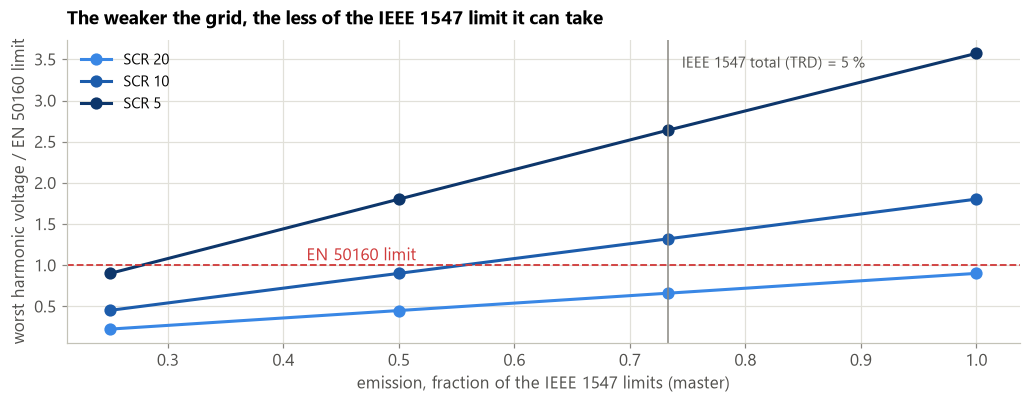

In [3]:
p = A.load("sweep_hil404_points.csv")
q = p[p.sweep == "master"]
fig, ax = A.panels(1, h=3.8)
rows = []
for g in A.GRIDS[1:]:
    x = q[q.grid == g].sort_values("master")
    ax[0].plot(x.master, x.EN50160_worst_ratio, "o-", color=A.GRID_COLOR[g], label=g)
    r = x.EN50160_worst_ratio.values; m = x.master.values
    allowed = np.interp(1.0, r, m) if r.max() > 1 else np.nan        # voltage is linear in emission
    rows.append({"grid": g, "largest master meeting EN 50160": allowed if r.max() > 1 else "> 1 (full request is fine)",
                 "worst ratio at master 1": r[-1], "binding order": int(x.EN50160_worst_order.iloc[-1])})
ax[0].axhline(1, color=A.BAD, ls="--", lw=1.2); ax[0].text(0.42, 1.06, "EN 50160 limit", color=A.BAD)
ax[0].axvline(0.733, color=A.MUTED, lw=1); ax[0].text(0.745, 3.4, "IEEE 1547 total (TRD) = 5 %", color=A.INK2, fontsize=9.5)
ax[0].set_xlabel("emission, fraction of the IEEE 1547 limits (master)"); ax[0].set_ylabel("worst harmonic voltage / EN 50160 limit")
ax[0].set_title("The weaker the grid, the less of the IEEE 1547 limit it can take")
ax[0].legend(loc="upper left")
al = pd.DataFrame(rows)
A.save(fig, "07_allowed_emission", q[["grid", "master", "THD_V_pct", "EN50160_worst_ratio", "EN50160_worst_order"]])
display(Markdown(A.md_table(al)))
claim("C7.1", "Largest uniform emission (fraction of IEEE 1547 limits) meeting EN 50160 at every order, SCR 10 / SCR 5",
      "%.2f / %.2f (SCR 20: full request is fine)" % (al.iloc[1, 1], al.iloc[2, 1]), "results/sweep_hil404_points.csv (sweep 'master')")

**Reading.** Each line is one grid. Above the red dashed line, at least one order breaks EN 50160. The
voltage grows in a straight line with emission, so the crossing point is the largest emission the grid
allows. The grey line is where IEEE 1547's own total limit (TRD 5 %) is met.

Note: the SCR 5 points in this sweep were taken at 750 V, 3 s after a step (notebook 06), so their
tracking was not settled. The voltage ratio is still close, because it depends mainly on the current
asked for and the grid impedance.

## One order at a time on the weakest grid

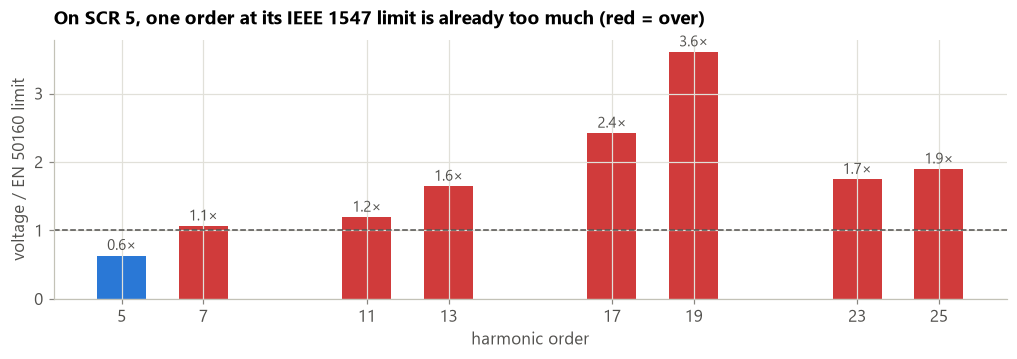

In [4]:
o = A.load("sweep_hil404_orders.csv")
o = o[(o.sweep == "single") & (o.order == o.only) & (o.grid == "SCR 5") & (o.order <= 25)].copy()
o["ratio"] = [v / A.EN50160[h] for v, h in zip(o.V_pct, o.order)]
fig, ax = A.panels(1, h=3.4)
ax[0].bar(o.order, o.ratio, 1.2, color=[A.BAD if r > 1 else A.USED for r in o.ratio])
ax[0].axhline(1, color=A.LIMIT, ls="--", lw=1)
for h, r in zip(o.order, o.ratio):
    ax[0].text(h, r + 0.08, "%.1f×" % r, ha="center", fontsize=9.5, color=A.INK2)
A.orders_axis(ax[0], list(o.order)); ax[0].set_ylabel("voltage / EN 50160 limit")
ax[0].set_title("On SCR 5, one order at its IEEE 1547 limit is already too much (red = over)")
A.save(fig, "07_single_order_SCR5", o[["order", "I_pct", "V_pct", "ratio"]])
claim("C7.2", "SCR 5, one order at a time at its IEEE 1547 limit: orders over EN 50160, and the worst",
      "%s; the %dth at %.1f×" % (", ".join(str(h) for h in o[o.ratio > 1].order), o.loc[o.ratio.idxmax(), "order"], o.ratio.max()),
      "results/sweep_hil404_orders.csv (sweep 'single')")

**Reading.** Even with only **one** order switched on at its own IEEE 1547 limit, a weak grid's voltage
goes over EN 50160 at most orders, and the 19th by more than three times. This happens on a simple R-L
grid, without any resonance. With cable capacitance and resonance in a real feeder, it can only matter
more; that is the next step and is not in this repository.

## Limits of this notebook
- One inverter on an R-L grid; no other loads or sources; X/R = 3 assumed.
- 10-cycle snapshots compared with limits defined for week-long statistics.

In [5]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C7.1 | Largest uniform emission (fraction of IEEE 1547 limits) meeting EN 50160 at every order, SCR 10 / SCR 5 | 0.55 / 0.28 (SCR 20: full request is fine) | results/sweep_hil404_points.csv (sweep 'master') |
| C7.2 | SCR 5, one order at a time at its IEEE 1547 limit: orders over EN 50160, and the worst | 7, 11, 13, 17, 19, 23, 25; the 19th at 3.6× | results/sweep_hil404_orders.csv (sweep 'single') |